# Lecture : Graph-based Visualization

## Lab 04 : Laplacian Eigenmaps 

### Xavier Bresson  


In [ ]:
# For Google Colaboratory
import sys, os
if 'google.colab' in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/04_Visualization'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pwd
    

In [1]:
# Load libraries
import numpy as np
import scipy.io
from matplotlib import pyplot
import matplotlib.pyplot as plt
import time
import sys; sys.path.insert(0, 'lib/')
import scipy.sparse.linalg
# import scipy.ndimage
from lib.utils import compute_pca, construct_knn_graph,graph_laplacian
import warnings; warnings.filterwarnings("ignore")
import torch


# PCA for MNIST

In [2]:
# MNIST dataset
mat = scipy.io.loadmat('datasets/MNIST_data.mat')
X = Xnumpy = mat['X']
n = X.shape[0]
d = X.shape[1]
C = mat['C'].squeeze()
print(n,d)

# extract a subset of data points
# idx_rand = torch.randperm(n)[:10000]; X = X[idx_rand,:]; C = C[idx_rand]; print(X.shape,C.shape)


60000 784


nb_pca: 3


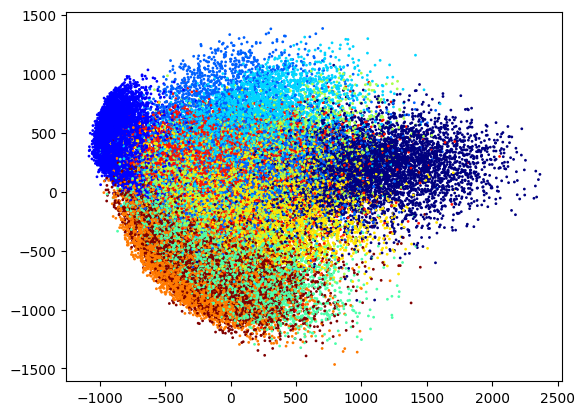

In [3]:
# PCA
nb_pca = 3
[PC,PD,EnPD] = compute_pca(X,nb_pca)
Xvis = PC[:,0]
Yvis = PC[:,1]
Zvis = PC[:,2]

# 2D Visualization
plt.figure(3)
plt.scatter(Xvis, Yvis, c=C, s=1, color=pyplot.jet())
plt.show()


In [4]:
# 3D Visualization
import plotly.graph_objects as go
data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1)) # data as points
# data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1, showscale=True)) # w/ colobar 
fig = go.Figure(data=[data]) 
fig.update_layout(margin=dict(l=0, r=0, b=0, t=25, pad=0)) # tight layout but t=25 required for showing title 
fig.update_layout(autosize=False, width=800, height=800, title_text="PCA MNIST") # figure size and title
# fig.update_layout(scene = dict(xaxis = dict(visible=False), yaxis = dict(visible=False), zaxis = dict(visible=False))) # no grid, no axis 
# fig.update_layout(scene = dict(xaxis_title = ' ', yaxis_title = ' ', zaxis_title = ' ')) # no axis name 
fig.update_layout(scene = dict(zaxis = dict(showgrid = True, showticklabels = False), zaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(yaxis = dict(showgrid = True, showticklabels = False), yaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(xaxis = dict(showgrid = True, showticklabels = False), xaxis_title = ' ') ) # no range values, no axis name, grid on
fig.show()


# LapEigMap for MNIST

## Question 1: LapEigMaps
Implement the code below to compute the three Laplacian eigenmaps that corresponding to the second, third and fourth smallest eigenvalues.

**Question**: why not use the first eigenvector that corresponds to the smallest eigenvalue?

**Answer**: 

batch_size 2000
Convert from numpy to pytorch
k-NN graph construction with euclidean distance
n, batch_size, num_batch, kNN, device: 60000 2000 30 10 cpu
batch idx: 1 / 30  time(sec): 2.219282865524292
batch idx: 2 / 30  time(sec): 4.404036045074463
batch idx: 3 / 30  time(sec): 6.64729905128479
batch idx: 4 / 30  time(sec): 9.172872304916382
batch idx: 5 / 30  time(sec): 11.777065992355347
batch idx: 6 / 30  time(sec): 13.992504119873047
batch idx: 7 / 30  time(sec): 16.332694053649902
batch idx: 8 / 30  time(sec): 18.96666121482849
batch idx: 9 / 30  time(sec): 21.797688007354736
batch idx: 10 / 30  time(sec): 24.28279709815979
batch idx: 11 / 30  time(sec): 27.117650985717773
batch idx: 12 / 30  time(sec): 29.593544960021973
batch idx: 13 / 30  time(sec): 32.08040714263916
batch idx: 14 / 30  time(sec): 34.48527503013611
batch idx: 15 / 30  time(sec): 37.03108191490173
batch idx: 16 / 30  time(sec): 39.861242055892944
batch idx: 17 / 30  time(sec): 42.58914089202881
batch idx: 18 / 

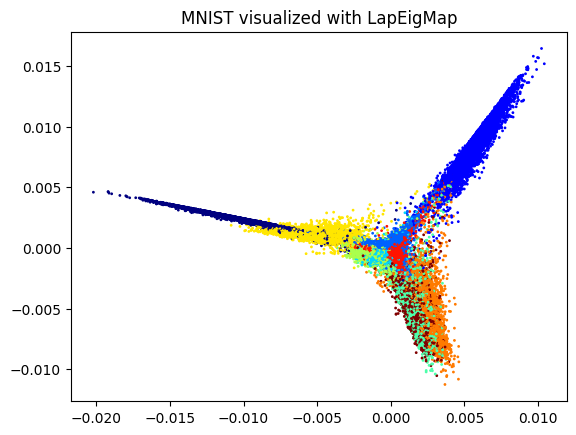

In [5]:
# Compute a k-NN graph
kNN = 10
dist = 'euclidean'
W = construct_knn_graph(X, kNN, dist)
#print(W)

# Laplacian Eigenmaps
start = time.time()

def sort(lamb, U):
    idx = lamb.argsort()
    return lamb[idx], U[:,idx]

def nldr_visualization(W):
    
    # Compute normalized graph Laplacian
    L = graph_laplacian(W)
    
    # Regularization for ill-posed graphs
    L = L + 1e-6 * scipy.sparse.identity(L.shape[0], dtype=W.dtype)

    ########### Your code here###################
    # Compute the first three Laplacian Eigenmaps X, Y, Z 
    
    # Sort eigenvalue from smallest to largest values
    
    # Coordinates of graph vertices in the low-dim embedding manifold
    lamb, U = sort(*scipy.sparse.linalg.eigsh(L, k=4, which='SM'))
    X, Y, Z = U[:,1], U[:,2], U[:,3]
    

    ####################################################
    return X,Y,Z


Xvis,Yvis,Zvis = nldr_visualization(W)
print('time(sec):',(time.time()-start)/1)

# 2D Visualization
plt.figure(3)
plt.scatter(Xvis, Yvis, c=C, s=1, color=pyplot.jet())
plt.title('MNIST visualized with LapEigMap') 
plt.show()


In [6]:
# 3D Visualization
import plotly.graph_objects as go
data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1)) # data as points
# data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1, showscale=True)) # w/ colobar 
fig = go.Figure(data=[data]) 
fig.update_layout(margin=dict(l=0, r=0, b=0, t=25, pad=0)) # tight layout but t=25 required for showing title 
fig.update_layout(autosize=False, width=800, height=800, title_text="MNIST visualized with LapEigMap") # figure size and title
# fig.update_layout(scene = dict(xaxis = dict(visible=False), yaxis = dict(visible=False), zaxis = dict(visible=False))) # no grid, no axis 
# fig.update_layout(scene = dict(xaxis_title = ' ', yaxis_title = ' ', zaxis_title = ' ')) # no axis name 
fig.update_layout(scene = dict(zaxis = dict(showgrid = True, showticklabels = False), zaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(yaxis = dict(showgrid = True, showticklabels = False), yaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(xaxis = dict(showgrid = True, showticklabels = False), xaxis_title = ' ') ) # no range values, no axis name, grid on
fig.show()
